# Chess Game Analysis

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn

In [9]:
df = pd.read_csv("/content/games.csv")
display(df)

,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
0,TZJHLljE,False,1.504210e+12,1.504210e+12,13,outoftime,white,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,Slav Defense: Exchange Variation,5
1,l1NXvwaE,True,1.504130e+12,1.504130e+12,16,resign,black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,Nimzowitsch Defense: Kennedy Variation,4
2,mIICvQHh,True,1.504130e+12,1.504130e+12,61,mate,white,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,King's Pawn Game: Leonardis Variation,3
3,kWKvrqYL,True,1.504110e+12,1.504110e+12,61,mate,white,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,Queen's Pawn Game: Zukertort Variation,3
4,9tXo1AUZ,True,1.504030e+12,1.504030e+12,95,mate,white,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,Philidor Defense,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,EfqH7VVH,True,1.499791e+12,1.499791e+12,24,resign,white,10+10,belcolt,1691,jamboger,1220,d4 f5 e3 e6 Nf3 Nf6 Nc3 b6 Be2 Bb7 O-O Be7 Ne5...,A80,Dutch Defense,2
20054,WSJDhbPl,True,1.499698e+12,1.499699e+12,82,mate,black,10+0,jamboger,1233,farrukhasomiddinov,1196,d4 d6 Bf4 e5 Bg3 Nf6 e3 exd4 exd4 d5 c3 Bd6 Bd...,A41,Queen's Pawn,2
20055,yrAas0Kj,True,1.499698e+12,1.499698e+12,35,mate,white,10+0,jamboger,1219,schaaksmurf3,1286,d4 d5 Bf4 Nc6 e3 Nf6 c3 e6 Nf3 Be7 Bd3 O-O Nbd...,D00,Queen's Pawn Game: Mason Attack,3
20056,b0v4tRyF,True,1.499696e+12,1.499697e+12,109,resign,white,10+0,marcodisogno,1360,jamboger,1227,e4 d6 d4 Nf6 e5 dxe5 dxe5 Qxd1+ Kxd1 Nd5 c4 Nb...,B07,Pirc Defense,4


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20058 entries, 0 to 20057
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              20058 non-null  object 
 1   rated           20058 non-null  bool   
 2   created_at      20058 non-null  float64
 3   last_move_at    20058 non-null  float64
 4   turns           20058 non-null  int64  
 5   victory_status  20058 non-null  object 
 6   winner          20058 non-null  object 
 7   increment_code  20058 non-null  object 
 8   white_id        20058 non-null  object 
 9   white_rating    20058 non-null  int64  
 10  black_id        20058 non-null  object 
 11  black_rating    20058 non-null  int64  
 12  moves           20058 non-null  object 
 13  opening_eco     20058 non-null  object 
 14  opening_name    20058 non-null  object 
 15  opening_ply     20058 non-null  int64  
dtypes: bool(1), float64(2), int64(4), object(9)
memory usage: 2.3+ MB


In [12]:
df["opening_name"].value_counts()

,count
opening_name,
Van't Kruijs Opening,368
Sicilian Defense,358
Sicilian Defense: Bowdler Attack,296
French Defense: Knight Variation,271
Scotch Game,271
...,...
Slav Defense: Two Knights Attack,1
Sicilian Defense: Richter-Rauzer Variation | Vitolins Variation,1
Queen's Gambit Declined: Exchange Variation | Reshevsky Variation,1


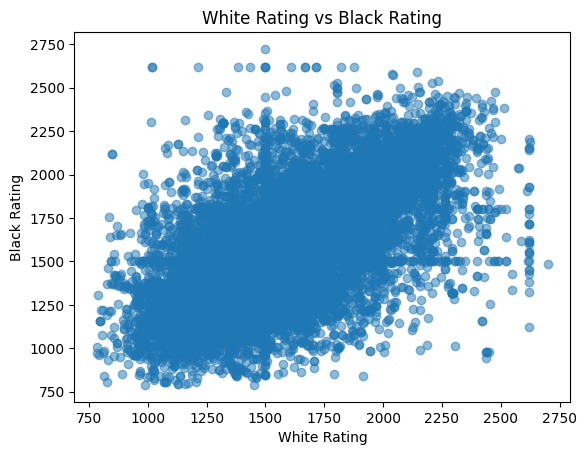

In [14]:
plt.scatter(df['white_rating'], df['black_rating'], alpha=0.5)
plt.xlabel('White Rating')
plt.ylabel('Black Rating')
plt.title('White Rating vs Black Rating')
plt.show()

(array([  48.,  132.,  351.,  731., 1070., 1818., 2172., 3246., 2336.,
        2226., 1807., 1516., 1056.,  609.,  467.,  283.,   87.,   63.,
          10.,   30.]),
 array([ 784. ,  879.8,  975.6, 1071.4, 1167.2, 1263. , 1358.8, 1454.6,
        1550.4, 1646.2, 1742. , 1837.8, 1933.6, 2029.4, 2125.2, 2221. ,
        2316.8, 2412.6, 2508.4, 2604.2, 2700. ]),
 <BarContainer object of 20 artists>)

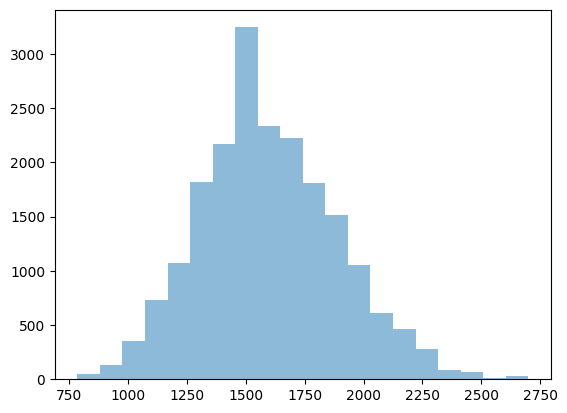

In [15]:
plt.hist(df['white_rating'], bins=20, alpha=0.5, label='White Rating')

(array([7.000e+01, 1.870e+02, 3.730e+02, 7.920e+02, 1.238e+03, 1.861e+03,
        2.263e+03, 3.272e+03, 2.347e+03, 2.140e+03, 1.782e+03, 1.378e+03,
        9.710e+02, 5.940e+02, 4.310e+02, 2.370e+02, 6.700e+01, 3.500e+01,
        1.900e+01, 1.000e+00]),
 array([ 789. ,  885.7,  982.4, 1079.1, 1175.8, 1272.5, 1369.2, 1465.9,
        1562.6, 1659.3, 1756. , 1852.7, 1949.4, 2046.1, 2142.8, 2239.5,
        2336.2, 2432.9, 2529.6, 2626.3, 2723. ]),
 <BarContainer object of 20 artists>)

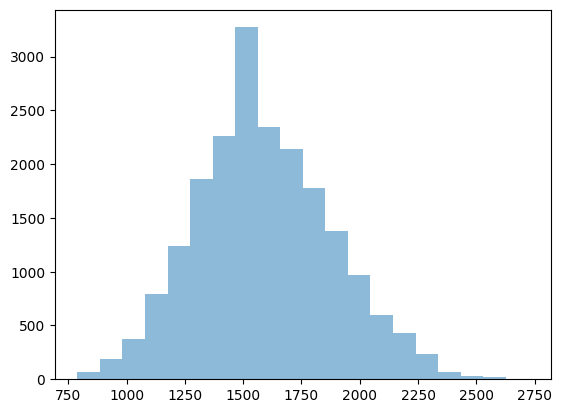

In [16]:
plt.hist(df['black_rating'], bins=20, alpha=0.5, label='Black Rating')

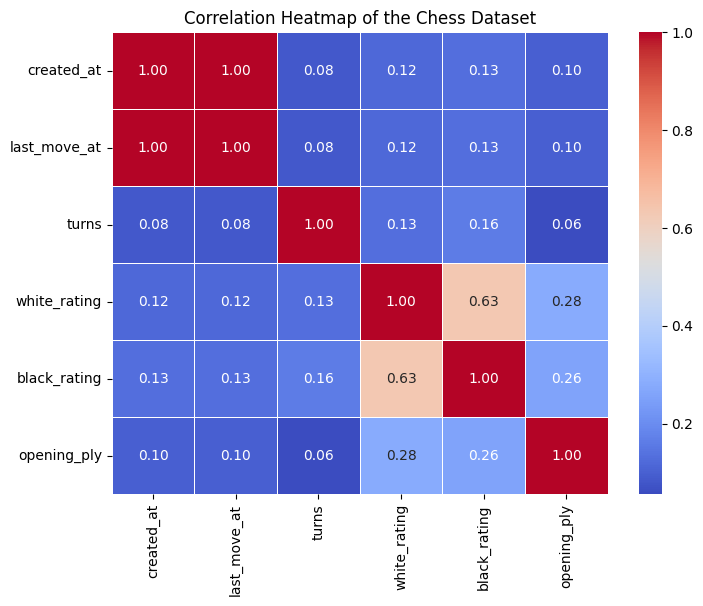

In [17]:
numerical_df = df.select_dtypes(include=[np.number])
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(8, 6))
seaborn.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of the Chess Dataset')
plt.show()

In [18]:
df ['id'].value_counts()

,count
id,
XRuQPSzH,5
Q0jogkvi,4
CxQlHSnq,4
O037dETy,4
CvakmVNb,4
...,...
clnqpkWZ,1
mucCs6SN,1
wtfZlRGa,1


In [19]:
for i in df.columns:
  print(f"--------------{i}--------------")
  print(df[i].value_counts())

--------------id--------------
id
XRuQPSzH    5
Q0jogkvi    4
CxQlHSnq    4
O037dETy    4
CvakmVNb    4
           ..
clnqpkWZ    1
mucCs6SN    1
wtfZlRGa    1
bgv3IQF9    1
Eo5epqXJ    1
Name: count, Length: 19113, dtype: int64
--------------rated--------------
rated
True     16155
False     3903
Name: count, dtype: int64
--------------created_at--------------
created_at
1.504210e+12    45
1.504140e+12    39
1.504200e+12    38
1.503860e+12    37
1.504050e+12    32
                ..
1.501677e+12     1
1.501677e+12     1
1.501998e+12     1
1.504011e+12     1
1.504013e+12     1
Name: count, Length: 13151, dtype: int64
--------------last_move_at--------------
last_move_at
1.504210e+12    46
1.504140e+12    39
1.504200e+12    35
1.503860e+12    34
1.503870e+12    33
                ..
1.499791e+12     1
1.499812e+12     1
1.499813e+12     1
1.499814e+12     1
1.499815e+12     1
Name: count, Length: 13186, dtype: int64
--------------turns--------------
turns
53     303
45     302
51     29

In [21]:
df.shape

(20058, 16)

In [22]:
df.duplicated().sum()

np.int64(429)

In [32]:
for i in df.columns:
  print(f"--------------{i}--------------")
  print(df[i].nunique())

--------------id--------------
19113
--------------rated--------------
2
--------------created_at--------------
13151
--------------last_move_at--------------
13186
--------------turns--------------
211
--------------victory_status--------------
4
--------------winner--------------
3
--------------increment_code--------------
400
--------------white_id--------------
9438
--------------white_rating--------------
1516
--------------black_id--------------
9331
--------------black_rating--------------
1521
--------------moves--------------
18920
--------------opening_eco--------------
365
--------------opening_name--------------
1477
--------------opening_ply--------------
23


In [33]:
df = df.drop_duplicates()
print(f"New shape after removing duplicates: {df.shape}")

New shape after removing duplicates: (19629, 16)


In [34]:
display(df.describe(include='all'))

,id,rated,created_at,last_move_at,turns,victory_status,winner,increment_code,white_id,white_rating,black_id,black_rating,moves,opening_eco,opening_name,opening_ply
count,19629,19629,1.962900e+04,1.962900e+04,19629.000000,19629,19629,19629,19629,19629.000000,19629,19629.000000,19629,19629,19629,19629.000000
unique,19113,2,NaN,NaN,NaN,4,3,400,9438,NaN,9331,NaN,18920,365,1477,NaN
top,nSvKFzXI,True,NaN,NaN,NaN,resign,white,10+0,ssf7,NaN,docboss,NaN,e4 e5,A00,Van't Kruijs Opening,NaN
freq,2,15817,NaN,NaN,NaN,10926,9792,7563,48,NaN,44,NaN,27,992,363,NaN
mean,NaN,NaN,1.483721e+12,1.483722e+12,60.458607,NaN,NaN,NaN,NaN,1596.090224,NaN,1588.324622,NaN,NaN,NaN,4.804422
std,NaN,NaN,2.809364e+10,2.809353e+10,33.502852,NaN,NaN,NaN,NaN,290.165038,NaN,290.164447,NaN,NaN,NaN,2.792791
min,NaN,NaN,1.376772e+12,1.376772e+12,1.000000,NaN,NaN,NaN,NaN,784.000000,NaN,789.000000,NaN,NaN,NaN,1.000000
25%,NaN,NaN,1.477530e+12,1.477530e+12,37.000000,NaN,NaN,NaN,NaN,1400.000000,NaN,1393.000000,NaN,NaN,NaN,3.000000
50%,NaN,NaN,1.495830e+12,1.495830e+12,55.000000,NaN,NaN,NaN,NaN,1567.000000,NaN,1562.000000,NaN,NaN,NaN,4.000000
75%,NaN,NaN,1.503107e+12,1.503110e+12,79.000000,NaN,NaN,NaN,NaN,1791.000000,NaN,1783.000000,NaN,NaN,NaN,6.000000


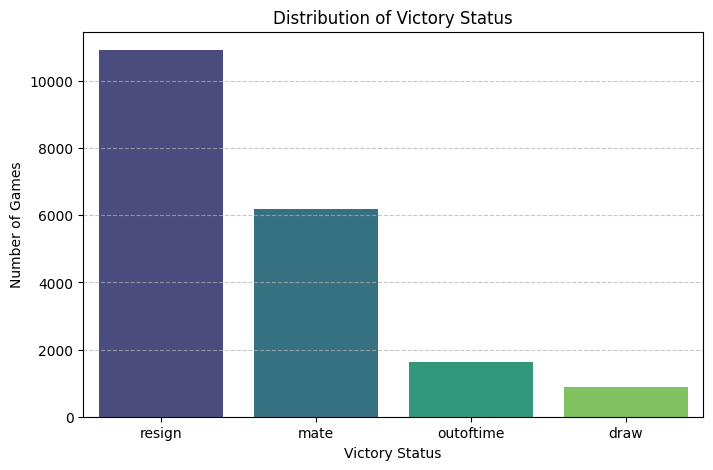

In [36]:
# Count the occurrences of each victory status
victory_counts = df['victory_status'].value_counts()

# Create the bar plot
plt.figure(figsize=(8, 5))
sns.barplot(x=victory_counts.index, y=victory_counts.values, palette='viridis', hue=victory_counts.index, legend=False)

# Add labels and title
plt.xlabel('Victory Status')
plt.ylabel('Number of Games')
plt.title('Distribution of Victory Status')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Display the plot
plt.show()

,count,mean,std,min,25%,50%,75%,max
victory_status,,,,,,,,
draw,874.0,84.209382,45.470768,2.0,48.0,87.0,115.0,259.0
mate,6188.0,65.460084,33.233386,4.0,42.0,59.0,82.0,222.0
outoftime,1641.0,72.906155,38.582076,1.0,48.0,72.0,96.0,349.0
resign,10926.0,53.856581,29.602119,1.0,33.0,50.0,70.0,218.0


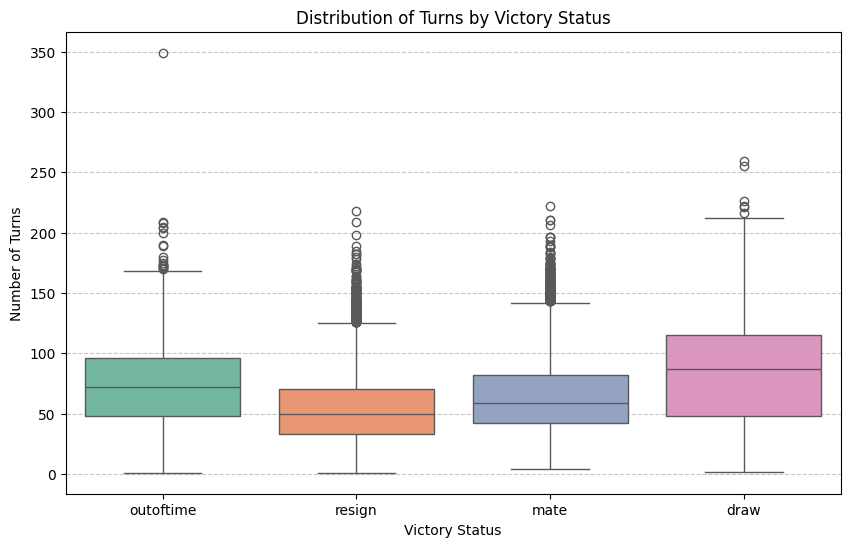

In [38]:
# Calculate descriptive statistics for turns grouped by victory_status
turns_summary = df.groupby('victory_status')['turns'].describe()
display(turns_summary)

# Create a boxplot to visualize the distribution of turns for each victory status
plt.figure(figsize=(10, 6))
sns.boxplot(x='victory_status', y='turns', data=df, palette='Set2', hue='victory_status', legend=False)

# Add labels and title
plt.xlabel('Victory Status')
plt.ylabel('Number of Turns')
plt.title('Distribution of Turns by Victory Status')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show plot
plt.show()

In [41]:
# Calculate Pearson correlation coefficients
corr_white = df['turns'].corr(df['white_rating'])
corr_black = df['turns'].corr(df['black_rating'])

print(f"Correlation between turns and White's rating: {corr_white:.4f}")
print(f"Correlation between turns and Black's rating: {corr_black:.4f}")

Correlation between turns and White's rating: 0.1291
Correlation between turns and Black's rating: 0.1598


,count,mean,median,std
opening_name,,,,
Philidor Defense #2,190,69.831579,63.0,36.633796
Queen's Pawn Game: Mason Attack,230,66.504348,61.5,31.943010
Indian Game,180,65.505556,56.0,36.478584
Caro-Kann Defense,196,64.887755,60.0,29.863581
Sicilian Defense: Bowdler Attack,294,64.734694,60.0,34.951517
Modern Defense,173,64.213873,59.0,33.469101
French Defense: Knight Variation,265,61.509434,56.0,32.089613
Scandinavian Defense: Mieses-Kotroc Variation,253,60.913043,55.0,33.240471
Queen's Pawn Game: Chigorin Variation,224,60.486607,54.0,33.406047


/tmp/ipykernel_5260/4157329663.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_openings, y='opening_name', x='turns', palette='coolwarm', order=opening_stats.index)


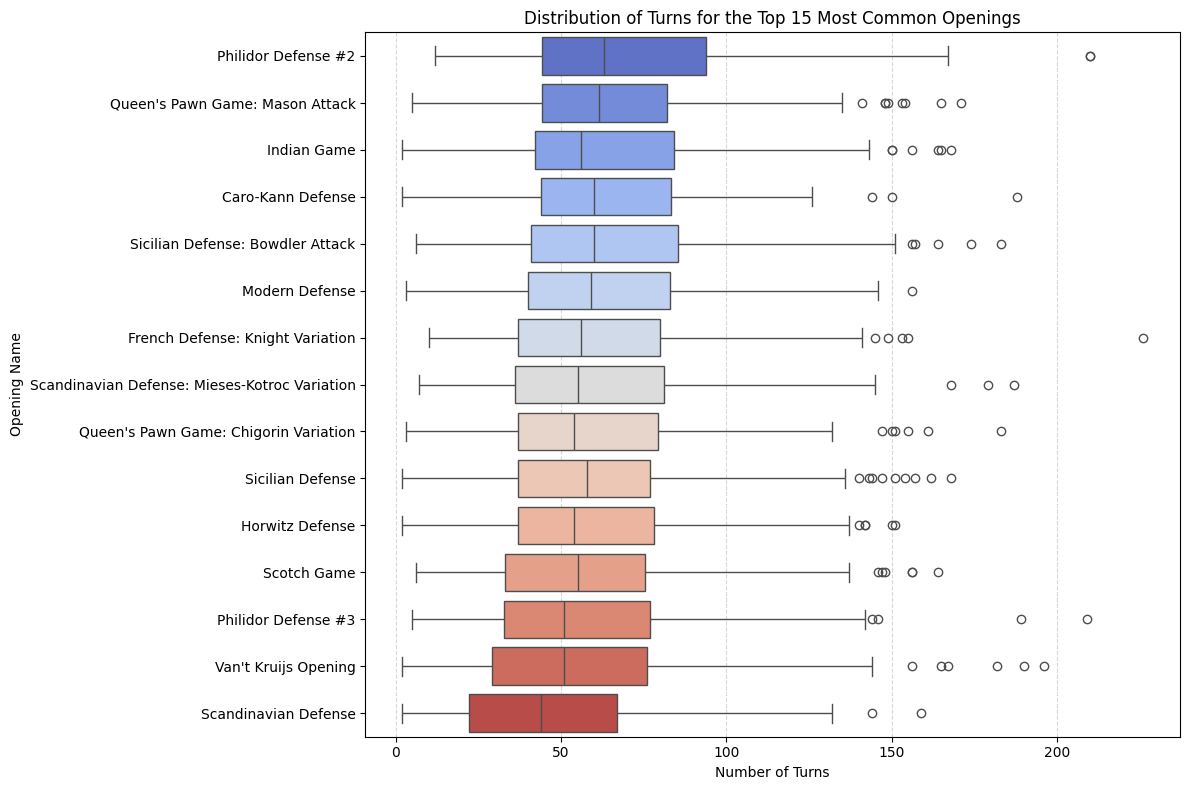

In [42]:
# Get the top 15 most common openings
top_openings = df['opening_name'].value_counts().nlargest(15).index

# Filter the dataset for these top openings
df_top_openings = df[df['opening_name'].isin(top_openings)]

# Calculate average and median turns for each top opening
opening_stats = df_top_openings.groupby('opening_name')['turns'].agg(['count', 'mean', 'median', 'std']).sort_values(by='mean', ascending=False)
display(opening_stats)

# Visualize the distribution of turns for the top openings
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
sns.boxplot(data=df_top_openings, y='opening_name', x='turns', palette='coolwarm', order=opening_stats.index)
plt.title('Distribution of Turns for the Top 15 Most Common Openings')
plt.xlabel('Number of Turns')
plt.ylabel('Opening Name')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [43]:
# Calculate win rates for each of the top 15 openings
win_rates = df_top_openings.groupby('opening_name')['winner'].value_counts(normalize=True).unstack(fill_value=0) * 100

# Join with total game count to keep track of sample size
win_rates = win_rates.join(df_top_openings['opening_name'].value_counts().to_frame('total_games'))

# Sort by White's win rate descending
win_rates = win_rates.sort_values(by='white', ascending=False)

# Format output for better readability
win_rates_styled = win_rates.style.format({
    'white': '{:.1f}%',
    'black': '{:.1f}%',
    'draw': '{:.1f}%',
    'total_games': '{:,.0f}'
})

display(win_rates_styled)

,black,draw,white,total_games
opening_name,,,,
Philidor Defense #3,34.0%,2.1%,63.8%,188
Scandinavian Defense: Mieses-Kotroc Variation,34.8%,2.4%,62.8%,253
Caro-Kann Defense,42.3%,3.6%,54.1%,196
Scotch Game,42.4%,4.2%,53.4%,264
Horwitz Defense,44.7%,2.4%,52.9%,208
Queen's Pawn Game: Mason Attack,44.3%,5.2%,50.4%,230
French Defense: Knight Variation,44.5%,5.3%,50.2%,265
Queen's Pawn Game: Chigorin Variation,47.8%,3.6%,48.7%,224
Modern Defense,49.7%,3.5%,46.8%,173


In [46]:
!pip install streamlit pandas numpy matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 71.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 98.3 MB/s eta 0:00:00


In [ ]:
!streamlit run app.py



2026-10-23 13:27:48.129 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.119.52.124:8501

